# Austin Crash Hotspots – Clustering Analysis

### Problem
Around 100 people die in traffic crashes in Austin every year. The city has a goal
called Vision Zero (zero traffic deaths), but it can't fix every road at once.

My question: Where in Austin do serious crashes keep happening?

I'll use clustering (K-Means, then HDBSCAN) to find these dangerous areas.

## Part 1. Load the Data
data source: https://data.austintexas.gov/Transportation-and-Mobility/Austin-Crash-Report-Data-Crash-Level-Records/y2wy-tgr5

In [2]:
import pandas as pd
import numpy as np

In [4]:
# Download crash data directly from Austin Open Data website
# https://data.austintexas.gov/api/views/y2wy-tgr5/rows.csv?accessType=DOWNLOAD

#'low_memory=False' reads the whole file in one go so pandas guesses each column’s type correctly. Without it, you may get a warning.

crashes = pd.read_csv('data/austin_crashes.csv', low_memory=False)
crashes.head()

,ID,Crash ID,crash_fatal_fl,case_id,rpt_block_num,rpt_street_name,rpt_street_sfx,crash_speed_limit,road_constr_zone_fl,latitude,...,Is deleted,Is temporary record,Law enforcement fatality count,Reported street prefix,Estimated Maximum Comprehensive Cost,Estimated Total Comprehensive Cost,Location ID,Location group,Address,Collision type
0,332565,13576956.0,False,132871113,7741,OLD SPICEWOOD SPRINGS RD,RD,-1,False,30.421712,...,False,False,0,NaN,25000,25000,1FDEDC038D,1.0,7741 OLD SPICEWOOD SPRINGS RD,ONE MOTOR VEHICLE - GOING STRAIGHT
1,333417,11167820.0,False,10-0271121,1100,N IH 35 NB,HWY,55,False,30.283356,...,False,False,0,NaN,200000,200000,2C8049EFF20,2.0,1100 N IH 35,ONE MOTOR VEHICLE - GOING STRAIGHT
2,333049,11432870.0,False,10-1541288,8900,E US 290 HWY EB,HWY,55,False,30.328928,...,False,False,0,NaN,25000,50000,0D9E4FFA531,2.0,8900 E US 290,SAME DIRECTION - ONE STRAIGHT-ONE STOPPED
3,333492,12318856.0,False,112711692,90,PLEASANT VALLEY,RD,30,False,30.252285,...,False,False,0,NaN,200000,600000,657F8BC8A7,1.0,PLEASANT VALLEY RD & CESAR CHAVEZ,OPPOSITE DIRECTION - ONE STRAIGHT-ONE LEFT TURN
4,333795,11794376.0,False,10-3470646,5100,IH 35 SB,HWY,0,False,30.309566,...,False,False,0,NaN,200000,250000,AC2E4EB5360,2.0,5100 N IH 35,SAME DIRECTION - ONE STRAIGHT-ONE STOPPED


In [5]:
crashes.shape

(235632, 47)

In [6]:
crashes.columns.tolist()

['ID',
 'Crash ID',
 'crash_fatal_fl',
 'case_id',
 'rpt_block_num',
 'rpt_street_name',
 'rpt_street_sfx',
 'crash_speed_limit',
 'road_constr_zone_fl',
 'latitude',
 'longitude',
 'crash_sev_id',
 'sus_serious_injry_cnt',
 'nonincap_injry_cnt',
 'poss_injry_cnt',
 'non_injry_cnt',
 'unkn_injry_cnt',
 'tot_injry_cnt',
 'death_cnt',
 'units_involved',
 'point',
 'motor_vehicle_death_count',
 'motor_vehicle_serious_injury_count',
 'bicycle_death_count',
 'bicycle_serious_injury_count',
 'pedestrian_death_count',
 'pedestrian_serious_injury_count',
 'motorcycle_death_count',
 'motorcycle_serious_injury_count',
 'other_death_count',
 'other_serious_injury_count',
 'onsys_fl',
 'private_dr_fl',
 'micromobility_serious_injury_count',
 'micromobility_death_count',
 'Crash timestamp (US/Central)',
 'Crash timestamp',
 'Is deleted',
 'Is temporary record',
 'Law enforcement fatality count',
 'Reported street prefix',
 'Estimated Maximum Comprehensive Cost',
 'Estimated Total Comprehensive Cost

In [7]:
crashes['Crash timestamp (US/Central)'].head()

0    10/14/2013 03:50:00 PM
1    01/27/2010 01:46:00 PM
2    06/03/2010 03:07:00 PM
3    09/28/2011 08:05:00 PM
4    12/13/2010 09:53:00 AM
Name: Crash timestamp (US/Central), dtype: object

## Part 2. Clean the Data

### Understand the 'Crash timestamp (US/Central)' column

In [8]:
crashes['Crash timestamp (US/Central)'].dtype
## dtype('O') means pandas sees this as TEXT. We need to convert it to a date.

dtype('O')

In [9]:
# Convert to a real date
# Format: 10/14/2013 03:50:00 PM  ->  month/day/year hour:minute:second AM/PM

crashes['Crash timestamp (US/Central)'] = pd.to_datetime(crashes['Crash timestamp (US/Central)'], format="%m/%d/%Y %I:%M:%S %p")
crashes['Crash timestamp (US/Central)'].head()

0   2013-10-14 15:50:00
1   2010-01-27 13:46:00
2   2010-06-03 15:07:00
3   2011-09-28 20:05:00
4   2010-12-13 09:53:00
Name: Crash timestamp (US/Central), dtype: datetime64[ns]

In [10]:
crashes['Crash timestamp (US/Central)'].min(), crashes['Crash timestamp (US/Central)'].max()

(Timestamp('2010-01-01 00:59:00'), Timestamp('2026-11-06 01:18:00'))

### Keep only 2019 to 2025

The data goes from 2010 to 2026. I'm keeping 7 full years (2019-2025):
- recent enough to show today's dangerous roads
- 2026 is not finished yet, so I leave it out

In [15]:
crashes_7yr=crashes[
    (crashes['Crash timestamp (US/Central)']>= '2019-01-01') &
    (crashes['Crash timestamp (US/Central)']< '2026-01-01')
].copy()

crashes_7yr.shape

(93431, 47)

### Keep only the columns we need

47 columns is too many. For this project I need:
- date -> when
- latitude, longitude -> where (this is what we will cluster!)
- death_cnt, sus_serious_injry_cnt -> how serious
- units_involved -> who was involved (car, pedestrian, bike...)
- crash_speed_limit -> speed limit of the road
- Address, Collision type -> extra details

In [17]:
df = crashes_7yr[['Crash timestamp (US/Central)','latitude', 'longitude',
                  'death_cnt', 'sus_serious_injry_cnt', 'units_involved',
                  'crash_speed_limit', 'Address', 'Collision type']].copy()

#Rename columns
df = df.rename(columns={
    'Crash timestamp (US/Central)':'crash_date',
    'sus_serious_injry_cnt':'serious_injuries', 
    'death_cnt':'deaths',     
    'crash_speed_limit':'speed_limits', 
    'Address':'address', 
    'Collision type':'collision_type'
})

df.head()

,crash_date,latitude,longitude,deaths,serious_injuries,units_involved,speed_limits,address,collision_type
60991,2019-10-05 12:14:00,30.298027,-97.709288,0,0,Passenger car,40,4600 AIRPORT BLVD,OTHER
61607,2020-03-11 07:06:00,30.434033,-97.669700,0,0,Passenger car,25,KORMAN & IH 35 SVRD,ANGLE - ONE STRAIGHT-ONE RIGHT TURN
62874,2019-01-01 02:25:00,30.227407,-97.770476,0,0,Passenger car,-1,1000 W BEN WHITE BLVD WB,ONE MOTOR VEHICLE - GOING STRAIGHT
62875,2019-01-08 18:04:00,30.258139,-97.812390,0,0,Passenger car,-1,2700 LOOP 360,SAME DIRECTION - BOTH GOING STRAIGHT-REAR END
62877,2019-01-08 21:27:00,30.215688,-97.833325,0,0,Passenger car,45,3700 W WM CANNON,ANGLE - ONE STRAIGHT-ONE LEFT TURN


In [18]:
df.shape

(93431, 9)

### Checking missing values

In [19]:
df.isnull().sum()

crash_date           0
latitude            28
longitude           28
deaths               0
serious_injuries     0
units_involved       0
speed_limits         0
address              5
collision_type       0
dtype: int64

In [20]:
df[df['latitude'].isnull()]

,crash_date,latitude,longitude,deaths,serious_injuries,units_involved,speed_limits,address,collision_type
72776,2019-06-22 00:56:00,NaN,NaN,0,0,Motor vehicle – other & Passenger car,-1,US 183 SVRD & STATE HIGHWAY 183 SVRD,ANGLE - ONE STRAIGHT-ONE STOPPED
72874,2019-09-02 01:30:00,NaN,NaN,0,0,Large passenger vehicle,30,708 E 6TH ST,ONE MOTOR VEHICLE - BACKING
72931,2019-07-31 23:32:00,NaN,NaN,0,0,Large passenger vehicle & Passenger car,-1,1500 W WILLIAM CANNON DR,ONE MOTOR VEHICLE - GOING STRAIGHT
73291,2019-07-30 16:21:00,NaN,NaN,0,0,Large passenger vehicle,15,300 JESTER CIR,ONE MOTOR VEHICLE - BACKING
73362,2019-08-16 09:41:00,NaN,NaN,0,0,Large passenger vehicle & Passenger car,-1,9617 ANDERSON MILL RD,SAME DIRECTION - BOTH GOING STRAIGHT-SIDESWIPE
73874,2019-09-11 13:08:00,NaN,NaN,0,0,Large passenger vehicle,75,14500 N LOOP 1 SVRD,ONE MOTOR VEHICLE - GOING STRAIGHT
74417,2019-08-13 10:15:00,NaN,NaN,0,0,Large passenger vehicle & Passenger car,5,2300 W WHITIS AVE,ONE MOTOR VEHICLE - BACKING
75427,2019-09-15 23:01:00,NaN,NaN,0,0,Passenger car,-1,937 REINLI ST,ONE MOTOR VEHICLE - BACKING
76592,2019-10-23 17:19:00,NaN,NaN,0,0,Motorcycle & Passenger car,80,700 S US 130,SAME DIRECTION - BOTH GOING STRAIGHT-REAR END
77411,2019-11-03 00:15:00,NaN,NaN,0,0,Passenger car,65,10210 N US 183,ONE MOTOR VEHICLE - GOING STRAIGHT


Only 28 crashes have no latitude/longitude. Clustering is based on location,

so a crash without a location can't be placed on the map.

28 out of ~93,000 is tiny (0.03%), so I will drop them.

In [21]:
df = df.dropna(subset=['latitude','longitude'])
df.shape

(93403, 9)

### Create a 'serious' column

Most crashes are minor (no one hurt). Vision Zero focuses on crashes where someone was

KILLED or SERIOUSLY INJURED. These are called KSI crashes.

serious = True  if deaths > 0 OR serious_injuries > 0

serious = False otherwise

In [23]:
df['serious'] = (df['deaths']>0) | (df['serious_injuries']>0)
df['serious'].value_counts()

False    89929
True      3474
Name: serious, dtype: int64

In [24]:
3474/89929 *100

3.86304751526204

In [26]:
# Also add a year column - useful for charts later
df['year']=df['crash_date'].dt.year
df.head()

,crash_date,latitude,longitude,deaths,serious_injuries,units_involved,speed_limits,address,collision_type,serious,year
60991,2019-10-05 12:14:00,30.298027,-97.709288,0,0,Passenger car,40,4600 AIRPORT BLVD,OTHER,False,2019
61607,2020-03-11 07:06:00,30.434033,-97.669700,0,0,Passenger car,25,KORMAN & IH 35 SVRD,ANGLE - ONE STRAIGHT-ONE RIGHT TURN,False,2020
62874,2019-01-01 02:25:00,30.227407,-97.770476,0,0,Passenger car,-1,1000 W BEN WHITE BLVD WB,ONE MOTOR VEHICLE - GOING STRAIGHT,False,2019
62875,2019-01-08 18:04:00,30.258139,-97.812390,0,0,Passenger car,-1,2700 LOOP 360,SAME DIRECTION - BOTH GOING STRAIGHT-REAR END,False,2019
62877,2019-01-08 21:27:00,30.215688,-97.833325,0,0,Passenger car,45,3700 W WM CANNON,ANGLE - ONE STRAIGHT-ONE LEFT TURN,False,2019


### save the clean data

In [27]:
df.to_csv('data/austin_crashes_clean.csv', index=False)

#verify
import os
os.path.exists('data/austin_crashes_clean.csv')

True

## Part 3. Exploratory Data Analysis (EDA)

### Question 1: How many serious crashes and deaths happen each year?

In [28]:
import matplotlib.pyplot as plt

In [29]:
yearly = df.groupby('year').agg(serious_crashes=('serious','sum'), deaths=('deaths','sum'))
yearly

,serious_crashes,deaths
year,,
2019,572,88
2020,454,92
2021,555,114
2022,573,117
2023,494,90
2024,456,97
2025,370,99


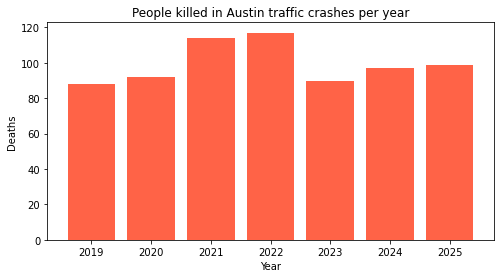

In [30]:
plt.figure(figsize=(8, 4))
plt.bar(yearly.index, yearly['deaths'], color='tomato')
plt.title('People killed in Austin traffic crashes per year')
plt.xlabel('Year')
plt.ylabel('Deaths')
plt.show()

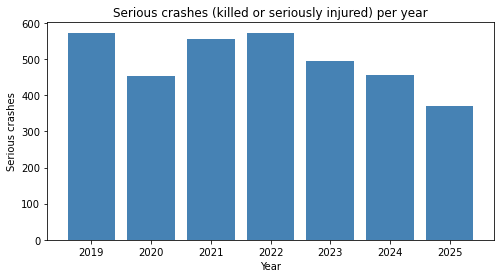

In [31]:
plt.figure(figsize=(8, 4))
plt.bar(yearly.index, yearly['serious_crashes'], color='steelblue')
plt.title('Serious crashes (killed or seriously injured) per year')
plt.xlabel('Year')
plt.ylabel('Serious crashes')
plt.show()

Observations:
- Around 90-117 people die every year. The worst years were 2021 and 2022.
- Deaths have NOT gone down, even though Austin's goal is zero deaths.
- Serious crashes dropped in 2025 (370). This could be real improvement, OR some
  2025 crash reports are not finished yet (the city says data can take weeks to finalize).
  Deaths in 2025 (99) did not drop, so I won't assume things got better.

### Question 2: Who gets hurt? Are pedestrians more at risk?

The 'units_involved' column tells us who was in the crash, e.g. "Passenger car & Pedestrian".

I'll create a column: pedestrian = True if a pedestrian was involved.

In [33]:
df['units_involved'].value_counts().head(10)

Passenger car                                              36098
Large passenger vehicle & Passenger car                    28928
Large passenger vehicle                                    13433
Motor vehicle – other & Passenger car                       3344
Large passenger vehicle & Motor vehicle – other             1377
Passenger car & Pedestrian                                  1173
Large passenger vehicle & Other/Unknown & Passenger car      998
Bicycle & Passenger car                                      873
Motorcycle & Passenger car                                   866
Large passenger vehicle & Pedestrian                         758
Name: units_involved, dtype: int64

In [34]:
df['pedestrian'] = df['units_involved'].str.contains('Pedestrian',na=False)
df['pedestrian'].value_counts()

#na=False means: if units_involved is empty, treat it as “no pedestrian”.

False    91135
True      2268
Name: pedestrian, dtype: int64

In [36]:
df.head()

,crash_date,latitude,longitude,deaths,serious_injuries,units_involved,speed_limits,address,collision_type,serious,year,pedestrian
60991,2019-10-05 12:14:00,30.298027,-97.709288,0,0,Passenger car,40,4600 AIRPORT BLVD,OTHER,False,2019,False
61607,2020-03-11 07:06:00,30.434033,-97.669700,0,0,Passenger car,25,KORMAN & IH 35 SVRD,ANGLE - ONE STRAIGHT-ONE RIGHT TURN,False,2020,False
62874,2019-01-01 02:25:00,30.227407,-97.770476,0,0,Passenger car,-1,1000 W BEN WHITE BLVD WB,ONE MOTOR VEHICLE - GOING STRAIGHT,False,2019,False
62875,2019-01-08 18:04:00,30.258139,-97.812390,0,0,Passenger car,-1,2700 LOOP 360,SAME DIRECTION - BOTH GOING STRAIGHT-REAR END,False,2019,False
62877,2019-01-08 21:27:00,30.215688,-97.833325,0,0,Passenger car,45,3700 W WM CANNON,ANGLE - ONE STRAIGHT-ONE LEFT TURN,False,2019,False


In [37]:
# What % of all crashes involve a pedestrian?
ped_share_of_crashes = df['pedestrian'].mean()*100
#.mean() on a True/False column gives the share of True values. True counts as 1 and False as 0, so the average equals the share.

# What % of all deaths happened in pedestrian crashes?
ped_share_of_deaths = df[df['pedestrian']]['deaths'].sum() / df['deaths'].sum() * 100

print("Pedestrian crashes as % of all crashes:", round(ped_share_of_crashes, 1))
print("Deaths in pedestrian crashes as % of all deaths:", round(ped_share_of_deaths, 1))

Pedestrian crashes as % of all crashes: 2.4
Deaths in pedestrian crashes as % of all deaths: 38.2


In [38]:
# Compare: when a crash happens, how often is it serious?
df.groupby('pedestrian')['serious'].mean()*100

pedestrian
False     3.031766
True     31.349206
Name: serious, dtype: float64

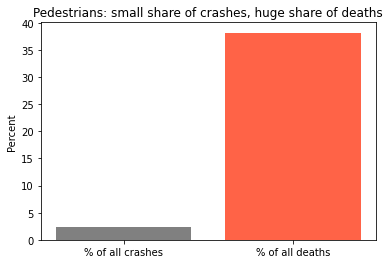

In [39]:
plt.figure(figsize=(6, 4))
plt.bar(['% of all crashes', '% of all deaths'], [ped_share_of_crashes, ped_share_of_deaths], color=['gray', 'tomato'])
plt.title('Pedestrians: small share of crashes, huge share of deaths')
plt.ylabel('Percent')
plt.show()

Observations:
- Only about 2.4% of crashes involve a pedestrian...
- ...but about 38% of all deaths happen in those crashes.
- When a pedestrian is involved, about 31% of crashes are serious, vs only about 3% otherwise.
  That's about 10 times more dangerous.

### Question 3: Where do serious crashes happen?

Let's plot every serious crash using longitude (x) and latitude (y).
This is like a simple map. This is the data we will cluster in Part 4.

In [40]:
serious = df[df['serious']].copy()
serious.shape

(3474, 12)

In [62]:
df.to_csv('data/serious.csv', index=False)

#verify
import os
os.path.exists('data/serious.csv')

True

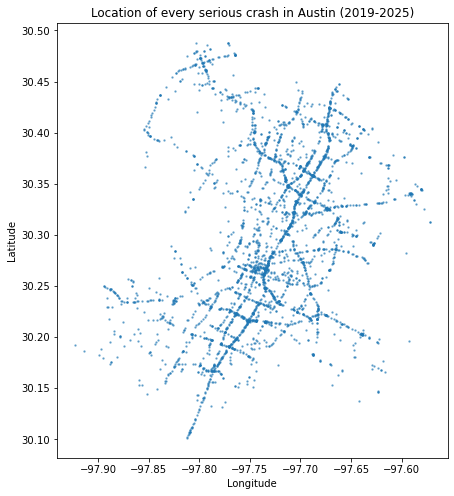

In [42]:
plt.figure(figsize=(7, 8))
plt.scatter(serious['longitude'], serious['latitude'], s=2, alpha=0.5)
plt.title('Location of every serious crash in Austin (2019-2025)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

#s=2 makes the dots small.
#alpha=0.5 makes them half see-through, so places with many crashes look darker.

Observations:
- Serious crashes form LINES. These are Austin's roads (the long one through
  the middle is the I-35 highway).
- Some areas are much darker (more crashes) than others.
- Next: can clustering find these dangerous areas for us?

### Question 4: Are crashes on faster roads more dangerous?

In [45]:
df['speed_limits'].value_counts().sort_index()

-1     18535
 5        35
 10      124
 15      276
 20      251
 25     1770
 30     6889
 34        6
 35    14306
 40     5775
 45    13499
 50     4760
 55     8376
 60     4782
 65     9600
 70     3449
 75      863
 79        1
 80       98
 85        8
Name: speed_limits, dtype: int64

About 18,500 crashes have speed_limit = -1. That means "not recorded".

These are NOT real speeds, so I will leave them out of this question.

In [48]:
# Group speed limits into ranges using pd.cut
# bins = the edges of each group: (0-30], (30-40], (40-50], (50-60], (60-90]

#pd.cut sorts numbers into ranges, like putting students into grade bands (A, B, C) based on their marks. 
#A speed of -1 is below 0, so it doesn’t fall into any range and becomes missing (NaN) automatically.

df['speed_group'] = pd.cut( df['speed_limits'],
                           bins=[0,30,40,50,60,90],
                           labels = ['30 or less','31-40','41-50','51-60','over 60'])

df['speed_group'].value_counts().sort_index()

30 or less     9345
31-40         20087
41-50         18259
51-60         13158
over 60       14019
Name: speed_group, dtype: int64

In [49]:
# Check: the -1 crashes became missing
df['speed_group'].isnull().sum()

18535

In [52]:
# Create a 'fatal' column: True if at least 1 person died
df['fatal'] = df['deaths'] >0

speed_table = df.groupby('speed_group').agg(crashes = ('serious','size'), 
                                            serious_pct= ('serious','mean'), 
                                            fatal_pct=('fatal','mean')
                                            )
speed_table['serious_pct'] = speed_table['serious_pct'] * 100
speed_table['fatal_pct'] = speed_table['fatal_pct'] * 100

speed_table.round(2)

#'size' counts the rows in each group.
#'mean' on True/False gives the share of True values

,crashes,serious_pct,fatal_pct
speed_group,,,
30 or less,9345,3.08,0.35
31-40,20087,4.08,0.65
41-50,18259,4.17,0.80
51-60,13158,4.01,0.86
over 60,14019,3.25,1.07


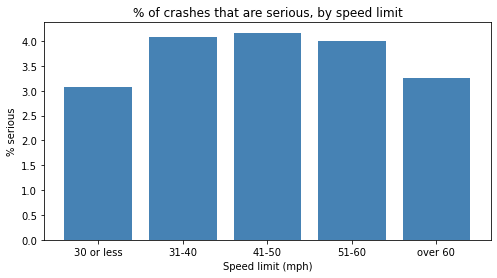

In [53]:
plt.figure(figsize=(8, 4))
plt.bar(speed_table.index.astype(str), speed_table['serious_pct'], color='steelblue')
plt.title('% of crashes that are serious, by speed limit')
plt.xlabel('Speed limit (mph)')
plt.ylabel('% serious')
plt.show()

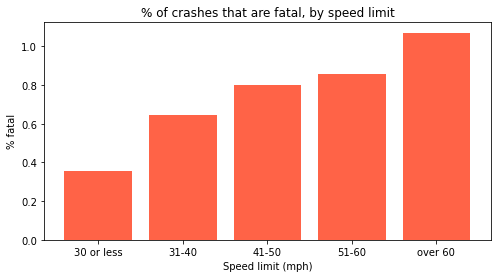

In [54]:
plt.figure(figsize=(8, 4))
plt.bar(speed_table.index.astype(str), speed_table['fatal_pct'], color='tomato')
plt.title('% of crashes that are fatal, by speed limit')
plt.xlabel('Speed limit (mph)')
plt.ylabel('% fatal')
plt.show()

Observations:
- Serious crash rate is about the same at every speed limit (3-4%). No clear pattern.
- But the FATAL rate keeps going up with speed:
  0.35% on roads 30 mph or less -> 1.07% on roads over 60 mph (about 3 times higher).
- So on faster roads, a crash is not more likely to hurt someone,
  but it is much more likely to KILL someone.
- Lesson: the measure I choose (serious vs fatal) changes the story.
  Always check more than one measure.

## Part 4. K-Means Clustering

#### Goal: group serious crashes by LOCATION to find dangerous areas of Austin.

Features: latitude and longitude only.

Data: the 3,474 serious crashes.

In [69]:
serious = pd.read_csv("data/serious.csv", parse_dates=['crash_date'])

#parse_dates tells pandas “this column is a date”, so we don’t have to convert it again.

,crash_date,latitude,longitude,deaths,serious_injuries,units_involved,speed_limits,address,collision_type,serious,year,pedestrian,kmeans_cluster
62883,2019-02-01 00:52:00,30.265649,-97.735063,1,0,E-scooter & Passenger car,35,500 N IH 35 SVRD,OPPOSITE DIRECTION - BOTH GOING STRAIGHT,True,2019,False,2
62948,2019-01-15 11:53:00,30.347022,-97.712473,0,1,Large passenger vehicle & Passenger car,45,N LAMAR BLVD & W ANDERSON LN,ANGLE - BOTH GOING STRAIGHT,True,2019,False,1


In [55]:
from sklearn.cluster import KMeans

In [56]:
X = serious[['latitude','longitude']]
X.head()

,latitude,longitude
62883,30.265649,-97.735063
62948,30.347022,-97.712473
63037,30.295185,-97.742857
63067,30.243492,-97.801917
63091,30.372274,-97.679237


### Do I need to scale the data?

Usually we scale features before K-Means (e.g. age 20-60 vs salary 30,000-200,000),

because K-Means uses distance and the bigger numbers would dominate.


Here BOTH features are in the same unit (degrees on a map), so I do NOT scale.

Scaling would actually stretch the map and distort real distances.

### Choosing k: the Elbow Method

Inertia = total distance between each crash and its centroid (how "tight" the groups are).

- More clusters -> lower inertia (always).
- I'm looking for the "elbow": the point where adding more clusters stops helping much.

In [57]:
inertia = []

for k in range(1,16):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)
    
inertia

#range(1, 16) tries k = 1, 2, 3 … 15.
#random_state=42 means you get the same result every time you run it.
#n_init=10 means K-Means tries 10 different starting points and keeps the best.

[34.19789742657026,
 15.614254824449997,
 11.460798831947985,
 8.262403198679321,
 6.9137174196484485,
 5.890778463447317,
 5.030386459104679,
 4.230107133979108,
 3.7027058192376003,
 3.1991936255003544,
 2.9339883059377154,
 2.6905547603705813,
 2.451675268468842,
 2.2531536305250537,
 2.0547665444988796]

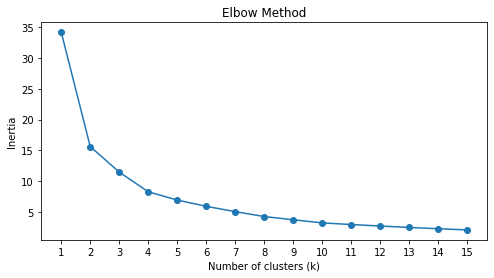

In [58]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 16), inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 16))
plt.show()

Observation:

- Inertia drops a lot from k=1 to k=4.
- After k=4 the line flattens - extra clusters don't help much.
- So the elbow is at k = 4.

### Fit K-Means with k = 4

In [61]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(X)

serious['kmeans_cluster'] = kmeans.labels_
serious.head()

#kmeans.labels_ is the group number (0, 1, 2 or 3) given to each crash.

,crash_date,latitude,longitude,deaths,serious_injuries,units_involved,speed_limits,address,collision_type,serious,year,pedestrian,kmeans_cluster
62883,2019-02-01 00:52:00,30.265649,-97.735063,1,0,E-scooter & Passenger car,35,500 N IH 35 SVRD,OPPOSITE DIRECTION - BOTH GOING STRAIGHT,True,2019,False,2
62948,2019-01-15 11:53:00,30.347022,-97.712473,0,1,Large passenger vehicle & Passenger car,45,N LAMAR BLVD & W ANDERSON LN,ANGLE - BOTH GOING STRAIGHT,True,2019,False,1
63037,2019-01-16 10:13:00,30.295185,-97.742857,0,1,Motorcycle,30,N GUADALUPE ST & W 29TH ST,ONE MOTOR VEHICLE - GOING STRAIGHT,True,2019,False,2
63067,2019-01-08 21:35:00,30.243492,-97.801917,1,0,Passenger car & Pedestrian,60,3600 S STATE HIGHWAY 360,ONE MOTOR VEHICLE - GOING STRAIGHT,True,2019,True,0
63091,2019-01-26 02:09:00,30.372274,-97.679237,0,1,Motor vehicle – other & Passenger car,70,9000 N IH 35,ONE MOTOR VEHICLE - GOING STRAIGHT,True,2019,False,1


In [66]:
# How many crashes in each cluster?
serious['kmeans_cluster'].value_counts().sort_index()

0     745
1    1167
2    1180
3     382
Name: kmeans_cluster, dtype: int64

In [67]:
# The centroids (center point of each cluster)
centroids = kmeans.cluster_centers_
centroids

array([[ 30.20204344, -97.79660505],
       [ 30.35998229, -97.68588457],
       [ 30.25335539, -97.7176804 ],
       [ 30.41886321, -97.7789623 ]])

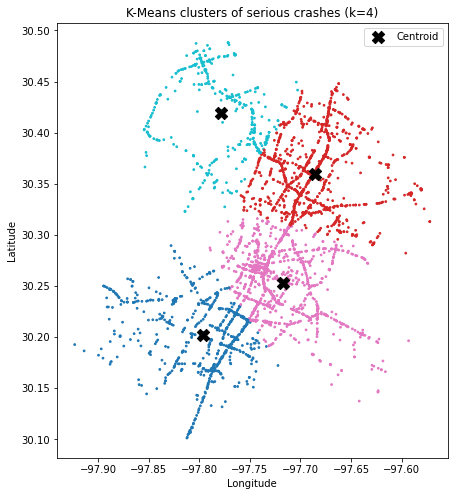

In [68]:
plt.figure(figsize=(7, 8))
plt.scatter(serious['longitude'], serious['latitude'], c=serious['kmeans_cluster'], cmap='tab10', s=3)
plt.scatter(centroids[:, 1], centroids[:, 0], c='black', s=150, marker='X', label='Centroid')
plt.title('K-Means clusters of serious crashes (k=4)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()

#c=serious['kmeans_cluster'] colors each dot by its cluster.
#centroids[:, 1] means “all rows, column 1”, which is the longitude. 
#Column 0 is latitude, because that’s the order we put in X. On a map, x = longitude and y = latitude.

Observations:

- K-Means split Austin into 4 big REGIONS (north-east, south-west, north-west, central/east).
- Each region is several miles wide.
- EVERY crash got put into a cluster.

## Part 5. Understanding the K-Means Clusters

### Step 1: Where is each cluster?

I'll use the average latitude and longitude of each cluster to see which part of Austin it is.

- Higher latitude = further NORTH
- Higher longitude (closer to zero, e.g. -97.69 vs -97.80) = further EAST

In [70]:
serious.groupby('kmeans_cluster')[['latitude','longitude']].mean()

,latitude,longitude
kmeans_cluster,,
0,30.202043,-97.796605
1,30.359982,-97.685885
2,30.253355,-97.717680
3,30.418863,-97.778962


Looking at the map and the averages:

- Cluster 0 -> lowest latitude, most west  -> South-West Austin

- Cluster 1 -> north, most east            -> North-East Austin

- Cluster 2 -> middle                      -> Central / East Austin

- Cluster 3 -> highest latitude, west      -> North-West Austin

In [72]:
cluster_names ={
    0: 'South-West',
    1: 'North-East',
    2: 'Central/East',
    3: 'North-West'
}

serious['kmeans_region'] = serious['kmeans_cluster'].map(cluster_names)
serious['kmeans_region'].value_counts()

Central/East    1180
North-East      1167
South-West       745
North-West       382
Name: kmeans_region, dtype: int64

### Step 2: Profile each region

For each region:
- how many serious crashes
- how many deaths
- % of serious crashes involving a pedestrian
- average speed limit (ignoring -1 = not recorded)

In [74]:
# Replace -1 (not recorded) with NaN, so it doesn't pull the average down
# NaN means “missing”. .mean() skips missing values automatically.

serious['speed_limits'] = serious['speed_limits'].replace(-1,np.nan)

In [75]:
region_profile = serious.groupby('kmeans_region').agg(
    serious_crashes = ('serious','size'),
    deaths = ('deaths', 'sum'),
    pedestrian_pct = ('pedestrian','mean'),
    avg_speed_limit = ('speed_limits', 'mean')
)

region_profile['pedestrian_pct'] = region_profile['pedestrian_pct'] * 100
#pedestrian_pct = the percent of serious crashes in that region that involved a pedestrian.

region_profile['deaths_per_100_crashes'] = region_profile['deaths']/ region_profile['serious_crashes']*100

region_profile.round(1)

,serious_crashes,deaths,pedestrian_pct,avg_speed_limit,deaths_per_100_crashes
kmeans_region,,,,,
Central/East,1180,195,20.8,44.0,16.5
North-East,1167,264,22.8,48.8,22.6
North-West,382,72,11.8,49.9,18.8
South-West,745,166,20.7,47.0,22.3


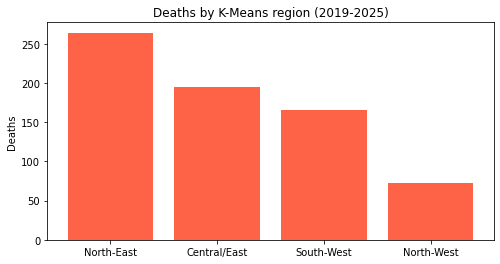

In [76]:
region_profile = region_profile.sort_values('deaths', ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(region_profile.index, region_profile['deaths'], color='tomato')
plt.title('Deaths by K-Means region (2019-2025)')
plt.ylabel('Deaths')
plt.show()

Observations:
- North-East has the most serious crashes and deaths (1,167 crashes, 264 deaths).
- North-West has the fewest, and fewer pedestrian crashes (about 12% vs about 21-23% elsewhere).
- But the other 3 regions look VERY similar: about 21-23% pedestrians, average speed about 44-49 mph.
  
  
  The regions don't tell us what is DIFFERENT about the dangerous places.

### Step 3: Can the city act on these regions?

If the city wants to fix roads in a region, which addresses should they go to?

Let's count how many DIFFERENT addresses are in each region,

and the top 3 addresses with the most serious crashes.

In [77]:
serious.groupby('kmeans_region')['address'].nunique()

kmeans_region
Central/East    1006
North-East      1027
North-West       357
South-West       678
Name: address, dtype: int64

In [82]:
# Top 3 addresses in the North-East region

serious[serious['kmeans_region'] == 'North-East']['address'].value_counts().head(3)

9300 N LAMAR BLVD                  4
E PARMER LN & SAMSUNG BLVD         4
RUTLAND DR & MEARNS MEADOW BLVD    4
Name: address, dtype: int64

Observation:

- The North-East region has about 1,027 DIFFERENT addresses.
- Even the worst single address has only about 4 serious crashes.
- So "North-East Austin is dangerous" is TRUE, but it's too big to act on.

  An engineer can't fix 1,000 addresses at once.

### Save the data with the K-Means results

In [84]:
serious.head(2)

,crash_date,latitude,longitude,deaths,serious_injuries,units_involved,speed_limits,address,collision_type,serious,year,pedestrian,kmeans_cluster,kmeans_region
62883,2019-02-01 00:52:00,30.265649,-97.735063,1,0,E-scooter & Passenger car,35.0,500 N IH 35 SVRD,OPPOSITE DIRECTION - BOTH GOING STRAIGHT,True,2019,False,2,Central/East
62948,2019-01-15 11:53:00,30.347022,-97.712473,0,1,Large passenger vehicle & Passenger car,45.0,N LAMAR BLVD & W ANDERSON LN,ANGLE - BOTH GOING STRAIGHT,True,2019,False,1,North-East


In [83]:
serious.to_csv("data/serious_crashes_kmeans.csv", index=False)

## Part 6. What K-Means Told Us - and What It Couldn't

### What K-Means did well
- Split Austin's 3,474 serious crashes into 4 regions (elbow method -> k = 4)
- Showed North-East Austin has the most serious crashes (1,167) and deaths (264)
- Showed North-West has far fewer pedestrian crashes (12% vs 21-23%)

### Limitations of K-Means for this problem
1. **Every crash is forced into a cluster.**
   Even a single crash on a quiet street joins a cluster.
   So "being in a cluster" does NOT mean "this is a dangerous place".

2. **The clusters are too big to act on.**
   Each region has about 400-1,000 different addresses.
   The city can't send engineers to 1,000 addresses.

3. **K-Means likes round groups.**
   But crashes happen along ROADS, in long thin lines.

4. **I had to choose k myself.**
   The elbow said 4, but the real number of dangerous places is clearly much more than 4.

### My question needs a different tool
K-Means answers: "How can I DIVIDE the city into k areas?"
My real question is: "Where do serious crashes CROWD together?"

On my scatter plot, I could see dark lines where dots are crowded - those are the places
I would send engineers. I need a method that finds crowded areas and ignores scattered crashes.
That method is **HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)**

In [85]:
import sklearn
sklearn.__version__

'0.24.2'

In [86]:
!pip install --upgrade scikit-learn

  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 2.2.0
    Uninstalling threadpoolctl-2.2.0:
      Successfully uninstalled threadpoolctl-2.2.0
  Attempting uninstall: joblib
    Found existing installation: joblib 1.1.0
    Uninstalling joblib-1.1.0:
      Successfully uninstalled joblib-1.1.0
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 0.24.2
    Uninstalling scikit-learn-0.24.2:
      Successfully uninstalled scikit-learn-0.24.2


## Part 7. HDBSCAN Clustering


Same data (3,474 serious crashes), same features (latitude, longitude).

This time: no k. Instead I set min_cluster_size = 10,

meaning a hotspot needs at least 10 serious crashes close together.

In [1]:
#(Kernel restarted after upgrading scikit-learn to 1.6.1 - reloading saved data)

from sklearn.cluster import HDBSCAN

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

serious = pd.read_csv('data/serious_crashes_kmeans.csv', parse_dates=['crash_date'])
serious.shape

(3474, 14)

In [4]:
X = serious[['latitude','longitude']]

hdb = HDBSCAN(min_cluster_size=10)

serious['hdbscan_cluster'] = hdb.fit_predict(X)
#fit_predict does two things in one step: it fits the model and gives back the cluster number for each crash.
#-1 means noise.

serious['hdbscan_cluster'].value_counts().head(10)

-1     1563
 17      78
 56      50
 58      49
 38      46
 18      44
 80      36
 0       36
 91      34
 8       34
Name: hdbscan_cluster, dtype: int64

In [6]:
serious['hdbscan_cluster'].value_counts()

-1     1563
 17      78
 56      50
 58      49
 38      46
       ... 
 13      10
 54      10
 69      10
 83      10
 34      10
Name: hdbscan_cluster, Length: 94, dtype: int64

In [5]:
# How many hotspots did HDBSCAN find?
num_hotspots = serious['hdbscan_cluster'].max()+1
num_hotspots

#Clusters are numbered 0, 1, 2 … so the biggest number + 1 = how many clusters there are. 
#Noise is -1, so it isn’t counted.

93

In [8]:
# How many crashes are noise?
noise = (serious['hdbscan_cluster'] == -1).sum()

print('Noise crashes:', noise)
print('Noise %:', round(noise/len(serious) * 100, 1))

Noise crashes: 1563
Noise %: 45.0


### Plot: hotspots vs noise

Grey = noise (scattered one-off crashes)

Red = crashes that belong to a hotspot

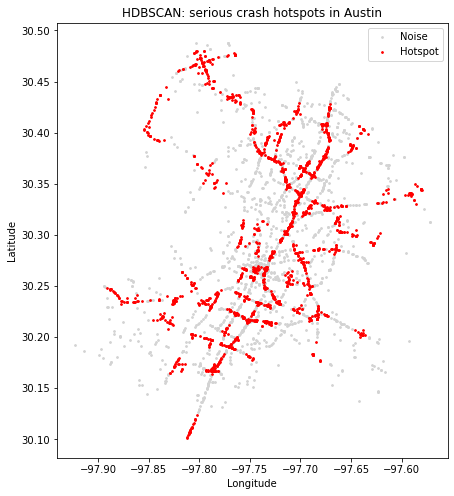

In [10]:
noise_points = serious[serious['hdbscan_cluster'] == -1]
hotspot_points = serious[serious['hdbscan_cluster'] != -1]

plt.figure(figsize=(7, 8))
plt.scatter(noise_points['longitude'], noise_points['latitude'], s=3, color='lightgray', label='Noise')
plt.scatter(hotspot_points['longitude'], hotspot_points['latitude'], s=3, color='red', label='Hotspot')
plt.title('HDBSCAN: serious crash hotspots in Austin')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()

### Plot: K-Means vs HDBSCAN side by side

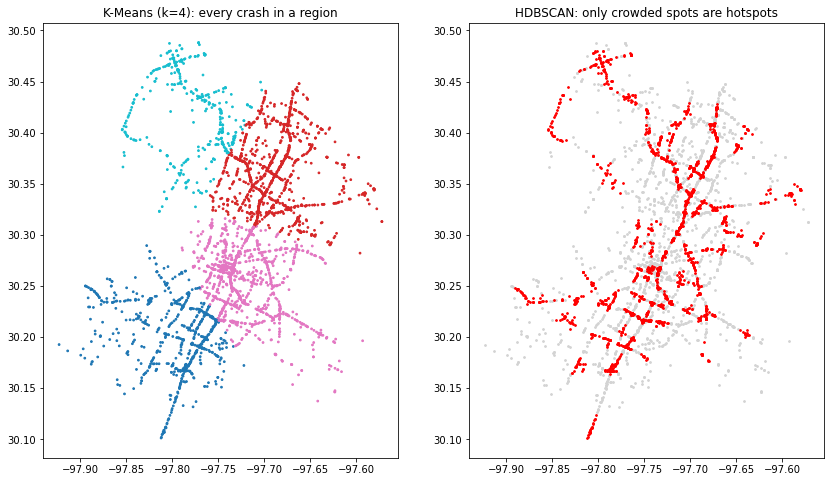

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 8))

# Left: K-Means
ax[0].scatter(serious['longitude'], serious['latitude'], c=serious['kmeans_cluster'], cmap='tab10', s=3)
ax[0].set_title('K-Means (k=4): every crash in a region')

# Right: HDBSCAN
ax[1].scatter(noise_points['longitude'], noise_points['latitude'], s=3, color='lightgray')
ax[1].scatter(hotspot_points['longitude'], hotspot_points['latitude'], s=3, color='red')
ax[1].set_title('HDBSCAN: only crowded spots are hotspots')

plt.show()

#plt.subplots(1, 2) makes 1 row with 2 charts side by side. ax[0] is the left chart and ax[1] is the right one.

### Profile the hotspots
For each hotspot: number of serious crashes, deaths, % pedestrian,

number of different addresses, and the most common address (to know WHERE it is).

In [13]:
hotspots = hotspot_points.groupby('hdbscan_cluster').agg(
    serious_crashes = ('serious','size'), #size means count
    deaths = ('deaths', 'sum'),
    pedestrian_pct = ('pedestrian','mean'),
    addresses = ('address', 'nunique'),
    main_address = ('address', lambda x: x.mode()[0])
)

#lambda x: x.mode()[0] is a tiny one-line function: “give me the most common address in this hotspot”.
#.mode() finds the most frequent value, and [0] takes the first one if there’s a tie.

hotspots['pedestrian_pct'] = hotspots['pedestrian_pct'] * 100

hotspots = hotspots.sort_values('serious_crashes', ascending = False)
hotspots.head(10).round(1)

,serious_crashes,deaths,pedestrian_pct,addresses,main_address
hdbscan_cluster,,,,,
17,78,9,9.0,74,ANDERSON MILL RD & POND SPRINGS RD
56,50,13,26.0,41,8700 S CONGRESS AVE
58,49,18,22.4,42,10500 N IH 35
38,46,12,34.8,39,1100 AIRPORT BLVD
18,44,6,38.6,43,4400 MANCHACA RD
0,36,3,2.8,35,N FM 620 RD & BOULDER LN
80,36,7,19.4,33,7400 N IH 35
91,34,7,26.5,25,N IH 35 SVRD & E 6TH ST
8,34,7,17.6,29,W US 290 & W WILLIAM CANNON DR


### Compare K-Means vs HDBSCAN

In [14]:
print("K-Means: number of groups =",serious['kmeans_cluster'].nunique())
print("K-Means: avg addresses per group =", round(serious.groupby('kmeans_cluster')['address'].nunique().mean()))
print("K-Means: % of crashes in a group = 100")
print()

print("HDBSCAN: number of hotspots =", num_hotspots)
print("HDBSCAN: avg addresses per hotspot =", round(hotspots['addresses'].mean()))
print("HDBSCAN: % of crashes in a hotspot =", round(len(hotspot_points) / len(serious) * 100, 1))

K-Means: number of groups = 4
K-Means: avg addresses per group = 767
K-Means: % of crashes in a group = 100

HDBSCAN: number of hotspots = 93
HDBSCAN: avg addresses per hotspot = 18
HDBSCAN: % of crashes in a hotspot = 55.0


In [15]:
# Where do deaths happen: in hotspots or in noise?

print("Deaths in hotspots:", hotspot_points['deaths'].sum())
print("Deaths in noise:", noise_points['deaths'].sum())

Deaths in hotspots: 380
Deaths in noise: 317


In [16]:
# Top 10 hotspots: what share of all serious crashes and deaths?

top10 = hotspots.head(10)

print('Top 10 hotspots- % of serious crashes:', round(top10['serious_crashes'].sum()/len(serious) *100, 1))
print("Top 10 hotspots - % of deaths:",round(top10['deaths'].sum()/serious['deaths'].sum() *100,1))

Top 10 hotspots- % of serious crashes: 12.6
Top 10 hotspots - % of deaths: 13.2


Observations:

- HDBSCAN found about 93 hotspots (K-Means: 4 regions).


- Each hotspot covers about 18 addresses (K-Means: about 767 per region).

  Hotspots are mostly STRETCHES OF ROAD (like ANDERSON MILL, N IH 35, S Congress Ave, Airport Blvd).
  
  
- About 45% of serious crashes are noise. Serious crashes are rare, so many happen at places that don't repeat. About half happen at repeat places - those are fixable.
  
  
- 380 of 697 deaths (55%) happened inside hotspots.


- The top 10 hotspots alone hold about 13% of all serious crashes and deaths.
  
  That's a short, actionable list for the city.

In [21]:
serious.to_csv("data/serious_crashes_clustered.csv", index=False)
hotspots.to_csv("data/hdbscan_hotspots.csv")

# Part 8. Conclusion

### K-Means vs HDBSCAN - final comparison

In [25]:
kmeans_avg_addresses = serious.groupby('kmeans_cluster')['address'].nunique().mean()
hdbscan_avg_addresses = hotspots['addresses'].mean()

kmeans_pct = 100
hdbscan_pct = round(len(hotspot_points) / len(serious) * 100, 1)

comparison = pd.DataFrame({
    'K-Means': [4, round(kmeans_avg_addresses), round(kmeans_pct, 1), 'No - every crash in a group'],
    'HDBSCAN': [num_hotspots, round(hdbscan_avg_addresses), round(hdbscan_pct, 1), 'Yes - 45% labeled noise']
}, index=['Number of groups', 'Avg addresses per group', '% of crashes in a group', 'Separates one-off crashes?'])

comparison

#pd.DataFrame({...}, index=[...]) builds a table by hand. Each key ('K-Means', 'HDBSCAN') becomes a column, 
#each list holds that column’s values, and index gives the row names.

,K-Means,HDBSCAN
Number of groups,4,93
Avg addresses per group,767,18
% of crashes in a group,100,55.0
Separates one-off crashes?,No - every crash in a group,Yes - 45% labeled noise


### 1. The problem
Austin's Vision Zero goal is zero traffic deaths, but about 100 people still die on Austin roads every year (697 deaths from 2019-2025). Out of 93,403 crashes in that period, 3,474 (3.7%) killed or seriously injured someone. The city can't fix every road at once, so it needs to know WHERE serious crashes keep happening. 

### 2. What I did
I used public crash data from the City of Austin Open Data Portal (235,632 records) and kept 7 full years, 2019-2025 (93,403 crashes). I focused on the 3,474 serious crashes (someone killed or seriously injured) and used two unsupervised clustering methods on their locations (latitude, longitude):

- K-Means (k = 4, chosen with the elbow method) gave a high-level view of which REGIONS
  of Austin have the most serious crashes. But the regions were too big to act on
  (about 767 addresses each).
  
  
- HDBSCAN then found specific HOTSPOTS where serious crashes crowd together
  (about 18 addresses each), and labeled scattered one-off crashes as noise.
  
Together, they drill down from "which part of the city" to "which road".

### 3. What I found
1. Pedestrians are only 2.4% of crashes but 38% of deaths. When a pedestrian is involved, 31% of crashes are serious, vs 3% otherwise (10x more dangerous).
   
   
2. Speed limit doesn't change how often a crash is serious (3-4% everywhere), but the fatal rate triples: 0.35% on roads 30 mph or less vs 1.07% over 60 mph.
   
   
3. K-Means (k=4): North-East Austin has the most serious crashes (1,167) and deaths (264), but each region covers about 767 addresses - too big to act on.
   
   
4. HDBSCAN found 93 hotspots (about 20 addresses each), mostly stretches of major roads like N IH-35, S Congress Ave and Airport Blvd. 55% of serious crashes happen in hotspots, and the other 45% are scattered one-off crashes (noise).
   
   
5. The top 10 hotspots alone hold about 13% of serious crashes and deaths.


### 4. My recommendation to the city

1. Fix the hotspots first: start with the top 10 HDBSCAN hotspots (about 13% of serious
   crashes). These are specific roads where engineers can redesign intersections,
   add signals and improve crossings.
   
   
2. Then fix the noise with city-wide changes: the other 45% of serious crashes don't
   repeat at one spot, so they need city-wide solutions such as lower speed limits
   on fast roads and better street lighting.
   
   
3. Focus on pedestrians and speed: pedestrians are 38% of deaths, so add safer
   crossings and pedestrian signals. Crashes on roads over 60 mph are 3x more likely
   to be fatal, so speed management on fast roads would save the most lives.

### 5. Limitations and next steps

- No traffic volume: busy roads have more crashes partly because more cars use them (the "spine of the city" roads). Next step: add traffic counts to compare crashes per car.


- Not every crash is reported: minor crashes, especially with pedestrians or bikes, may never reach the police.

  
- Results depend on my settings: min_cluster_size = 10 gave 93 hotspots. Next step: test 5 and 20 and check the top hotspots stay the same.


- Where, not why: clustering shows WHERE crashes happen, not WHY. Next step: study road design, lighting and speeding at the top hotspots.

# Appendix

### Concept Summary: K-Means vs HDBSCAN (my reference notes)

**Clustering** = grouping similar things together, without labels telling the computer what the groups are.

#### K-Means
- How it works: pick k -> place k centroids -> each point joins the nearest centroid
  -> centroids move to the middle of their group -> repeat until nothing changes
- I must choose k (use the elbow method)
- EVERY point joins a group
- Likes round, similar-sized groups
- Analogy: splitting a school into 4 houses - every student must join one,
  even if they have no friends there

#### HDBSCAN
- Full form: Hierarchical Density-Based Spatial Clustering of Applications with Noise
  - Density-Based -> finds places where points are CROWDED together
  - with Noise -> points not in a crowd are labeled -1 (noise), not forced into a group
  - Hierarchical -> checks crowds of many sizes, so I don't choose k
- Main setting: min_cluster_size = smallest crowd that counts as a cluster
- Groups can be ANY shape (e.g. long lines along roads)
- Analogy: finding the real friend groups in a school - kids who are always alone
  are not forced into a group

#### History (each method fixes the one before)
| Year | Method | What it added |
|---|---|---|
| 1950s-60s | K-Means | simple, fast grouping |
| 1996 | DBSCAN | crowded areas of any shape + noise |
| 2013 | HDBSCAN | no need to choose a distance; works for busy AND quiet areas |

#### When to use which
- Want to DIVIDE everything into k groups (e.g. customer types)? -> **K-Means**
- Want to FIND crowded spots and ignore the rest (e.g. crash hotspots)? -> **HDBSCAN**

#### Key idea
Noise is not garbage. For crashes, noise means "one-off crash, not a dangerous place" -
that is useful information for the city too.